# Point Cloud Classification Under Distribution Shift: Partial Views, Missing Points and Real Scans

- Point cloud data preparation
- Data visualisation
- Model training
- Model testing: supervised, zero-shot, random point removal
- Test-time adaptation: ModelNet40 → ScanObjectNN

Model: PointMLP, trained for 300 epochs on ModelNet40 (`checkpoints/pointMLP_baseline_best.pth`).
The cells below run small examples and load the saved results; the full experiments are run from the terminal (commands in each section).

In [1]:
import sys, json, h5py, numpy as np, pandas as pd, torch
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from pc_utils import *
from pointmlp import load_pointmlp, pointMLP
P, R = ROOT / "data/processed", ROOT / "outputs/results"
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())

torch 2.7.1+cu118 | CUDA: True


## Point cloud data preparation

ModelNet objects are triangle meshes (`.off`). Points are sampled uniformly on the surface (area-weighted),
then centred and scaled to the unit sphere.

In [2]:
v, f = read_off(ROOT / "data/raw/ModelNet40/chair/test/chair_0890.off")
pts = normalize_unit_sphere(sample_surface(v, f, 2048, np.random.default_rng(0)))
print(f"mesh: {len(v)} vertices, {len(f)} faces -> point cloud {pts.shape}, max radius {np.linalg.norm(pts, axis=1).max():.3f}")

mesh: 1658 vertices, 2996 faces -> point cloud (2048, 3), max radius 1.000


```bash
python scripts/prepare_data.py          # train 2048 points, test 32,768 points per object
```

In [3]:
for f in sorted(P.glob("*.h5")):
    with h5py.File(f) as h:
        k = "data" if "data" in h else "points"
        print(f"{f.name:46s} {str(h[k].shape):20s}")

modelnet10_test_32768.h5                       (908, 32768, 3)     
modelnet10_test_full_1024.h5                   (908, 1024, 3)      
modelnet10_test_full_2048.h5                   (908, 2048, 3)      
modelnet10_test_hpr_1024.h5                    (908, 1024, 3)      
modelnet10_test_hpr_2048.h5                    (908, 2048, 3)      
modelnet10_test_hpr_raw.h5                     (10681989, 3)       
modelnet10_test_removal_contiguous_10.h5       (908, 922, 3)       
modelnet10_test_removal_contiguous_20.h5       (908, 819, 3)       
modelnet10_test_removal_contiguous_30.h5       (908, 717, 3)       
modelnet10_test_removal_contiguous_40.h5       (908, 614, 3)       
modelnet10_test_removal_contiguous_50.h5       (908, 512, 3)       
modelnet10_test_removal_uniform_10.h5          (908, 922, 3)       
modelnet10_test_removal_uniform_20.h5          (908, 819, 3)       
modelnet10_test_removal_uniform_30.h5          (908, 717, 3)       
modelnet10_test_removal_uniform_40.h5          (

### Single-view test sets: Hidden Point Removal (HPR)

A sensor only sees the surfaces that face it. HPR (Katz et al., 2007) keeps the points visible from a camera:

1. translate the points so that the camera is at the origin;
2. spherical flip: $p' = p + 2(R-\lVert p\rVert)\,p/\lVert p\rVert$, with $R = \max\lVert p\rVert\cdot10^{3}$;
3. keep the points whose flipped copy lies on the convex hull of the flipped points and the camera.

| Parameter | Value |
|---|---|
| Camera distance | 4 |
| Azimuth | 45/135/225/315° ± 15° |
| Elevation | 15–30° |

Each object is stored with all visible points, and downsampled with FPS to 2048 and to 1024 points.

```bash
python scripts/make_hpr_testset.py
```

In [4]:
with h5py.File(P / "modelnet40_test_32768.h5") as h:
    dense = h["data"][0]
cam, az, el = three_quarter_camera(np.random.default_rng(0))
vis = hidden_point_removal(dense, cam, gamma=3)
print(f"camera azimuth {az:.0f}, elevation {el:.0f}: {len(vis)} of {len(dense)} points visible ({len(vis) / len(dense):.0%})")

camera azimuth 308, elevation 16: 11280 of 32768 points visible (34%)


### Random point removal (test sets only)

- **Uniform:** randomly chosen points are removed over the whole object, with no point chosen twice. The object stays complete but becomes evenly sparser, like low-density scanning.
- **Contiguous:** one random point is chosen and its nearest neighbours are removed until the target number is reached. This leaves one ball-shaped hole, like occlusion or a missing part.

Ratios 10–50% of the 1024 points, ModelNet40 and ModelNet10 test sets.

```bash
python scripts/make_removal_sets.py
```

In [5]:
with h5py.File(P / "modelnet40_test_full_1024.h5") as h:
    x = h["data"][0]
for method in ["uniform", "contiguous"]:
    kept = remove_points(x, 307, method, np.random.default_rng(0))
    removed = x[~(x[:, None] == kept[None]).all(-1).any(1)]
    spread = np.linalg.norm(removed - removed.mean(0), axis=1).mean()
    print(f"{method:10s} 30%: {len(x)} -> {len(kept)} points; removed points lie {spread:.2f} from their centre on average")

uniform    30%: 1024 -> 717 points; removed points lie 0.44 from their centre on average
contiguous 30%: 1024 -> 717 points; removed points lie 0.19 from their centre on average


### ScanObjectNN (real scans)

The three official test sets (OBJ_ONLY; OBJ_BG with background; PB_T50_RS with rotation and scaling),
reduced to the 11 classes shared with ModelNet40 and rotated from Y-up to Z-up.

```bash
python scripts/prepare_scanobjectnn.py
```

In [6]:
for v in ["obj_only", "obj_bg", "pb_t50_rs"]:
    with h5py.File(P / f"scanobjectnn_{v}.h5") as h:
        print(f"{v:10s} {h['data'].shape}  per class {np.bincount(h['label'][:]).tolist()}")
print("classes:", list(SCANOBJECTNN_SHARED))

obj_only   (475, 2048, 3)  per class [22, 75, 78, 30, 42, 42, 49, 24, 42, 54, 17]
obj_bg     (475, 2048, 3)  per class [22, 75, 78, 30, 42, 42, 49, 24, 42, 54, 17]
pb_t50_rs  (2362, 2048, 3)  per class [110, 372, 390, 150, 204, 210, 241, 120, 210, 270, 85]
classes: ['bed', 'cabinet', 'chair', 'desk', 'display', 'door', 'shelf', 'sink', 'sofa', 'table', 'toilet']


## Data visualisation

Columns: mesh, full point cloud, HPR, HPR FPS 2048, HPR FPS 1024 (one camera per row).

![HPR examples](../docs/figures/hpr_car_armadillo_bunny_piano_spatial.png)

`python scripts/visualize.py` writes all figures to `outputs/figures/` (colour and greyscale): HPR figures for
ModelNet40 and ModelNet10, random point removal, ScanObjectNN examples, and one test object per class.
Figures for other objects: `python scripts/visualize_select.py` asks for the dataset, objects, figure type, style and camera.

## Model training

PointMLP (Ma et al., ICLR 2022). Each of its four stages samples anchor points with FPS, groups 24 neighbours
per anchor, normalises each group (geometric affine module), and applies residual MLP blocks and max pooling.

In [7]:
m = pointMLP(40)
print(f"PointMLP: {sum(p.numel() for p in m.parameters()) / 1e6:.2f} M parameters\n")
print((ROOT / "configs/train.yaml").read_text())

PointMLP: 13.24 M parameters

# PointMLP training on ModelNet40 (settings of the official PointMLP code)
#
# python scripts/train_pointmlp.py --config configs/train.yaml [--epochs 50 ...]

run_name: pointmlp_modelnet40_300ep    # outputs/training/<run_name>/

# data
train_file: data/processed/modelnet40_train_2048.h5   # made by scripts/prepare_data.py
test_file: data/processed/modelnet40_test_full_1024.h5  # made by scripts/make_hpr_testset.py
num_points: 1024
num_classes: 40

# augmentation
scale_low: 0.6667         # per-axis scale U[2/3, 3/2]
scale_high: 1.5
shift_range: 0.2          # per-axis shift U[-0.2, 0.2]

# model
model: pointMLP           # pointMLP or pointMLPElite

# optimisation
epochs: 300
batch_size: 32
learning_rate: 0.1        # SGD
momentum: 0.9
weight_decay: 0.0002
min_lr: 0.005             # cosine schedule
label_smoothing: 0.2
grad_clip: 1.0            # gradient norm clipping

# runtime
workers: 8
seed: null                # integer for deterministic runs
eval_

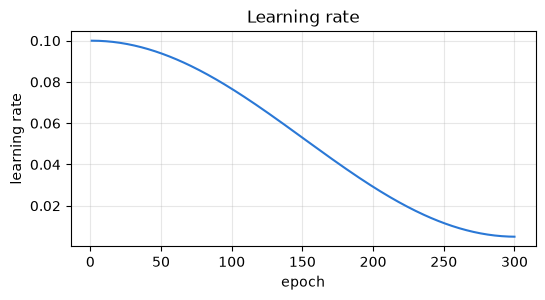

In [8]:
import yaml, matplotlib.pyplot as plt
%matplotlib inline
cfg = yaml.safe_load(open(ROOT / "configs/train.yaml"))
e = np.arange(cfg["epochs"])
lr = cfg["min_lr"] + (cfg["learning_rate"] - cfg["min_lr"]) * (1 + np.cos(np.pi * e / cfg["epochs"])) / 2
plt.figure(figsize=(6, 2.8)); plt.plot(e + 1, lr, color="#2a78d6")
plt.xlabel("epoch"); plt.ylabel("learning rate"); plt.title("Learning rate"); plt.grid(alpha=.3); plt.show()

```bash
bash train.sh                                    # 300 epochs in the background
tail -f outputs/training/pointmlp_modelnet40_300ep/train.log
RESUME=1 bash train.sh                           # resume
```

## Model testing

| Setting | Test data |
|---|---|
| Supervised | complete ModelNet40 objects (1024 and 2048 points) |
| Zero-shot | ModelNet40 single-view HPR; ModelNet10 complete and HPR; random point removal |

```bash
python scripts/test_supervised.py
python scripts/test_zeroshot.py
python scripts/test_zeroshot_clip.py
```

In [9]:
model = load_pointmlp(ROOT / "checkpoints/pointMLP_baseline_best.pth")
for name in ["full_1024", "hpr_1024", "removal_contiguous_50"]:
    with h5py.File(P / f"modelnet40_test_{name}.h5") as h:
        idx = np.arange(0, 2468, 309)
        X, y = h["data"][:][idx], h["label"][:, 0][idx]
    with torch.no_grad():
        pred = model(torch.from_numpy(X).cuda().permute(0, 2, 1)).argmax(1).cpu().numpy()
    print(name)
    for t, p in zip(y, pred):
        print(f"  {'correct' if t == p else 'wrong  '}  true {MODELNET40_CLASSES[t]:12s} predicted {MODELNET40_CLASSES[p]}")

full_1024
  correct  true airplane     predicted airplane
  correct  true bookshelf    predicted bookshelf
  correct  true chair        predicted chair
  wrong    true dresser      predicted night_stand
  correct  true mantel       predicted mantel
  correct  true piano        predicted piano
  correct  true sink         predicted sink
  correct  true toilet       predicted toilet
hpr_1024
  correct  true airplane     predicted airplane
  wrong    true bookshelf    predicted curtain
  correct  true chair        predicted chair
  wrong    true dresser      predicted table
  correct  true mantel       predicted mantel
  correct  true piano        predicted piano
  correct  true sink         predicted sink
  wrong    true toilet       predicted mantel
removal_contiguous_50
  correct  true airplane     predicted airplane
  correct  true bookshelf    predicted bookshelf
  correct  true chair        predicted chair
  wrong    true dresser      predicted night_stand
  correct  true mantel    

In [10]:
res = {**json.loads((R / "supervised_results.json").read_text()), **json.loads((R / "zeroshot_results.json").read_text())}
clip = json.loads((R / "clip_results.json").read_text())
rows = [{"test set": k, "PointMLP OA": 100 * v["OA"], "PointMLP mAcc": 100 * v["mAcc"],
         "CLIP OA": 100 * clip[k]["OA"] if k in clip else None}
        for k, v in res.items() if k != "checkpoint"]
pd.DataFrame(rows).set_index("test set").round(2)

,PointMLP OA,PointMLP mAcc,CLIP OA
test set,,,
modelnet40/full_1024,92.99,89.57,39.67
modelnet40/full_2048,93.07,89.92,44.29
modelnet40/hpr_1024,66.98,65.80,45.83
modelnet40/hpr_2048,64.10,62.96,47.49
modelnet40/hpr_raw,51.54,48.37,47.65
modelnet10/full_1024,94.93,94.86,37.00
modelnet10/hpr_1024,73.68,73.14,42.40
modelnet40/removal_uniform_10,92.99,89.84,35.58
modelnet40/removal_uniform_20,92.95,89.45,32.62


![Random point removal](../docs/figures/removal_curves.png)

### Zero-shot with CLIP

Each point cloud is rendered as 9 depth images and compared with text prompts such as "a depth map of a chair."
(PointCLIP, Zhang et al., 2022). The class names are plain text, so any list of names can be used.

![PointMLP and CLIP](../docs/figures/pointmlp_vs_clip.png)

In [11]:
from zeroshot import CLIPZeroShot
cfg = json.loads((R / "clip_results.json").read_text())["config"]
zs = CLIPZeroShot(cfg["clip"], classes=["chair", "airplane", "car", "dog", "banana", "guitar"], background=cfg["background"])
with h5py.File(P / "modelnet40_test_full_1024.h5") as h:
    x = h["data"][int(np.flatnonzero(h["label"][:, 0] == MODELNET40_CLASSES.index("airplane"))[0])]
probs = torch.softmax(zs.logits(torch.from_numpy(x)[None]), 1)[0].cpu().numpy()
for c, p in sorted(zip(zs.classes, probs), key=lambda t: -t[1]):
    print(f"{c:10s} {p:6.1%}")
del zs; torch.cuda.empty_cache()

airplane    99.8%
dog          0.1%
banana       0.1%
car          0.0%
chair        0.0%
guitar       0.0%


## Test-time adaptation: ModelNet40 → ScanObjectNN

The model adapts while it is tested, using only unlabelled test batches (one pass, batches of 64, 3 seeds, model reset for every run).

| Method | What is adapted |
|---|---|
| Source only | nothing |
| BN-adapt | BatchNorm statistics from the test batch |
| TENT | BatchNorm affine parameters, entropy minimisation |
| SHOT-IM | all layers except the classifier, entropy minimisation and diversity |
| T3A | classifier replaced by prototypes from confident test features |
| BN+T3A | BN-adapt and T3A |
| SAR | BatchNorm affine parameters, entropy minimisation on reliable samples, sharpness-aware |

```bash
python scripts/test_tta.py          # ~10 min
```

Example: source only and BN-adapt on OBJ_BG (one seed).

In [12]:
import importlib.util
spec = importlib.util.spec_from_file_location("tta_run", ROOT / "scripts/test_tta.py")
tta_run = importlib.util.module_from_spec(spec); spec.loader.exec_module(tta_run)
from tta import Adapter
X, y = tta_run.load("obj_bg", 0)
order = np.random.default_rng(0).permutation(len(X))
for method in ["source_only", "bn_adapt"]:
    pred = tta_run.run(Adapter(model, method, tta_run.GROUPS), X, order)
    print(f"{method:12s} OA {100 * (pred == y).mean():.1f}%")

source_only  OA 41.9%


bn_adapt     OA 44.8%


In [13]:
t = json.loads((R / "tta_summary.json").read_text())
methods = ["source_only", "bn_adapt", "tent", "shot_im", "t3a", "bn_t3a", "sar"]
pd.DataFrame({m: {v: f"{100 * t[v][m]['OA']:.1f} ± {100 * t[v][m]['OA_std']:.1f}" for v in t} for m in methods})

,source_only,bn_adapt,tent,shot_im,t3a,bn_t3a,sar
obj_only,48.2 ± 0.8,50.8 ± 1.2,51.4 ± 1.5,52.0 ± 1.9,47.5 ± 1.1,52.8 ± 1.4,50.8 ± 1.2
obj_bg,42.2 ± 0.4,45.7 ± 0.7,45.9 ± 0.6,47.2 ± 0.4,42.5 ± 0.8,46.7 ± 0.8,45.7 ± 0.7
pb_t50_rs,35.5 ± 0.6,36.9 ± 0.7,36.7 ± 0.5,36.4 ± 0.2,35.4 ± 0.5,36.6 ± 0.5,37.0 ± 0.8


![TTA](../docs/figures/tta_scanobjectnn.png)

## Summary

- **Supervised:** 93.0% on complete ModelNet40 objects.
- **Single-view HPR:** 67.0%; box-shaped classes such as dresser, wardrobe, glass box and xbox are the most confused.
- **ModelNet10:** 94.9% on complete objects, 73.7% with HPR.
- **Random point removal:** uniform removal barely changes PointMLP (92.7% at 50%); contiguous removal lowers it to 73.2%. CLIP falls with both.
- **CLIP:** 37–48% on complete and HPR objects, without any 3D training.
- **Test-time adaptation on ScanObjectNN:** BN+T3A and SHOT-IM add up to 4–5 points; T3A alone does not help.